In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
import sys, platform, json, importlib.metadata, torch
assert not torch.cuda.is_available(), 'CPU teaching lane unexpectedly sees CUDA'
identity = dict(executable=sys.executable, prefix=sys.prefix, python=platform.python_version(), platform=platform.platform(), cuda_available=torch.cuda.is_available(), torch_cuda_build=torch.version.cuda, packages={name:importlib.metadata.version(name) for name in ['torch','numpy','matplotlib','nbformat','nbclient','ipykernel','transformers','tokenizers','peft']})
print('__DONGXI_KERNEL_IDENTITY__:' + json.dumps(identity, sort_keys=True))

__DONGXI_KERNEL_IDENTITY__:{"cuda_available": false, "executable": "/tmp/dongxi-cs336-g9l7v90r/venv/bin/python", "packages": {"ipykernel": "7.4.0", "matplotlib": "3.10.8", "nbclient": "0.11.0", "nbformat": "5.11.1", "numpy": "2.5.3", "peft": "0.20.0", "tokenizers": "0.23.2", "torch": "2.14.1+cpu", "transformers": "5.18.0"}, "platform": "Linux-6.17.0-1031-nvidia-aarch64-with-glibc2.39", "prefix": "/tmp/dongxi-cs336-g9l7v90r/venv", "python": "3.12.3", "torch_cuda_build": null}


# One text, several tokenizer contracts

A tokenizer can preserve the decoded text while changing the model's IDs and cost. Which boundaries must be frozen before a token count or likelihood comparison means anything?

This original CPU microscope wraps the existing `ByteBPE`. It is not a GPT-2/Qwen implementation. The BPE algorithm is reused; segmentation, control admission and record framing are the changed mechanisms. No model download is needed. Predicted results are followed immediately by executable references and explanations. Companion reasoning: [worked notes](05_tokenizer_contracts-solutions.md).

In [2]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(root / "src"))
import math, json
import matplotlib.pyplot as plt
from dongxi_llms.tokenizer_contracts import (
    TokenizerContracts, ByteScore, ByteScoringContract, aggregate_byte_scores)


## Prediction — which boundaries survive a merge?

Train on repeated `ab cd`. Predict whether whole-record merges can produce one token spanning the space, and whether a word/space segmentation permits that same token.

## Checkpoint — isolate one policy

Write the predicted token counts before execution. Keep text and merge budget fixed; change only segmentation. Decode both results and explain why identical text does not imply identical ID streams.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

whole record [259] 'ab cd' bf7ab2366bc3
words/spaces [256, 32, 257] 'ab cd' 6d1e6a3ef1fa


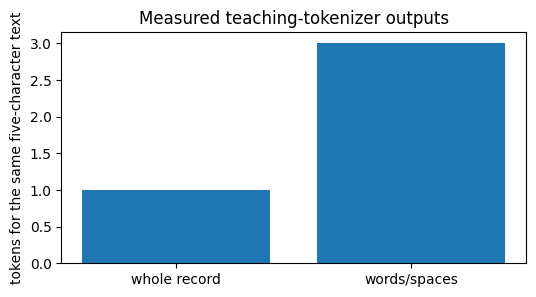

In [3]:
whole = TokenizerContracts.train(["ab cd"] * 10, 12)
segmented = TokenizerContracts.train(["ab cd"] * 10, 12, segmentation="words")
variants = {"whole record": whole, "words/spaces": segmented}
for label, tok in variants.items():
    ids = tok.encode("ab cd")
    print(label, ids, repr(tok.decode(ids)), tok.identity[:12])
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(list(variants), [len(t.encode("ab cd")) for t in variants.values()])
ax.set(ylabel="tokens for the same five-character text", title="Measured teaching-tokenizer outputs")
plt.show()

### Reference explanation

The whole-record reference produces one token; segmentation produces three. This is a boundary intervention, not a claim that fewer tokens improve language understanding. Read the bar height as sequence positions; the input text is the same. The configured `words` regex splits words, whitespace and punctuation and is explicitly independent of production tokenizer rules. The displayed cell regenerates the figure.

![Reference plot: Reference solution. Axis labels identify the mechanism quantities.](../../figures/chapter-02/cs336-05_tokenizer_contracts-01.png)

Read this preview alongside the explanation above. Regenerate it by running the adjacent reference cell; simulated curves and retained measurements keep their stated evidence labels.


## Prediction — can a control marker become ordinary merge data?

Two configured markers overlap: `<STOP>` and `<STOP><STOP>`. Predict which ID the doubled marker receives under longest-match recognition.

## Checkpoint — admission and isolation

Compare recognized controls with rejected reserved text. State whether a user literally typing a control string should be recognized, rejected or treated as ordinary text; that choice belongs to the input contract.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

In [4]:
control = TokenizerContracts.train(["ab<STOP>cd"] * 6, 12,
    special_tokens=("<STOP>", "<STOP><STOP>"))
text = "ab<STOP><STOP>cd<STOP>"
ids = control.encode(text)
print("IDs:", ids, "special IDs:", control.special_ids)
print("Decoded:", control.decode(ids))
assert ids.count(control.special_ids["<STOP><STOP>"]) == 1
assert not any(b"STOP" in p for p in control.model.pieces)
reject = TokenizerContracts(control.model, special_tokens=("<STOP>",), special_policy="reject")
try:
    reject.encode("a user literally typed <STOP>")
except ValueError as error:
    print("Declared rejected-input variant:", error)

IDs: [256, 259, 257, 258] special IDs: {'<STOP>': 258, '<STOP><STOP>': 259}
Decoded: ab<STOP><STOP>cd<STOP>
Declared rejected-input variant: A reserved marker appeared in ordinary input


### Reference explanation

Special spans are separated before BPE training and encoding. The doubled marker wins by the declared longest-match policy, and control IDs cannot be produced by merging ordinary segments. Recognition is not always the appropriate user-input policy: the rejected variant enforces a different trust boundary. No Qwen marker identity is inferred from these original strings.

## Prediction — do chunks mean separate records?

A trained token represents `garden`. Predict the ID streams for `['gar', 'den']` when they are independent records versus chunks of one record.

## Checkpoint — a runnable broken variant

Compare both streams with whole-text encoding. Explain why decoding alone misses the broken equivalence check. Then deliberately exceed the chunk buffer limit.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

whole [260] records [258, 259] chunks [260]
Bounded record guard: Buffered record exceeds declared character limit


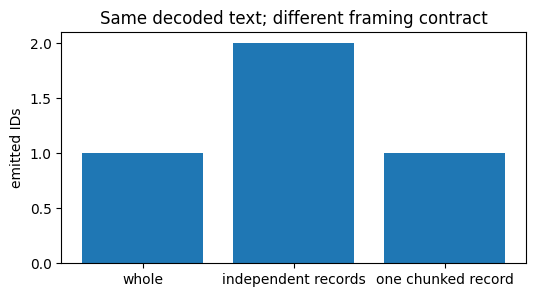

In [5]:
framed = TokenizerContracts.train(["garden"] * 6, 10)
whole_ids = framed.encode("garden")
record_ids = list(framed.encode_iterable(["gar", "den"], framing="records"))
chunk_ids = list(framed.encode_iterable(["gar", "den"], framing="chunks"))
print("whole", whole_ids, "records", record_ids, "chunks", chunk_ids)
assert chunk_ids == whole_ids and record_ids != whole_ids
assert framed.decode(record_ids) == "garden"
try:
    list(framed.encode_iterable(["gar", "den"], framing="chunks", max_record_chars=5))
except ValueError as error:
    print("Bounded record guard:", error)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["whole", "independent records", "one chunked record"], [len(whole_ids), len(record_ids), len(chunk_ids)])
ax.set(ylabel="emitted IDs", title="Same decoded text; different framing contract")
plt.show()

### Reference explanation

Independent encoding breaks a cross-boundary merge but still decodes to the same text. The record-framed iterator yields IDs lazily per record and inserts no EOS. Chunk mode buffers the entire single record before encoding, so its memory is proportional to that record; it does not promise constant memory for an arbitrary stream. The positive size guard fails before buffering beyond its declared character budget. The plot compares actual ID counts.

![Reference plot: Reference solution. Axis labels identify the mechanism quantities.](../../figures/chapter-02/cs336-05_tokenizer_contracts-02.png)

Read this preview alongside the explanation above. Regenerate it by running the adjacent reference cell; simulated curves and retained measurements keep their stated evidence labels.


## Prediction — what does a round trip preserve?

Predict whether NFC-normalizing `cafe` plus a combining acute preserves the original code-point sequence. Also predict whether a lone UTF-8 byte can be decoded strictly.

## Checkpoint — bind the saved rules

Serialize/reload the tokenizer, then corrupt a policy field. Distinguish preserved normalized text, preserved IDs, and rejected serialized identity.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

In [6]:
normalized = TokenizerContracts.train(["café"], 6, normalization="NFC")
reloaded = TokenizerContracts.from_json(normalized.to_json())
source = "cafe\u0301"
print("source", repr(source), "decoded", repr(reloaded.decode(reloaded.encode(source))))
assert reloaded.identity == normalized.identity
broken = json.loads(normalized.to_json())
broken["tokenizer"]["normalization"] = "none"
try:
    TokenizerContracts.from_json(json.dumps(broken))
except ValueError as error:
    print("Corruption rejected:", error)
try:
    normalized.decode([230])
except UnicodeDecodeError:
    print("A partial UTF-8 sequence fails strict decoding")
replacement = TokenizerContracts(normalized.model, decode_errors="replace")
print("Explicit replacement policy:", repr(replacement.decode([230])))

source 'café' decoded 'café'
Corruption rejected: Serialized identity does not match content
A partial UTF-8 sequence fails strict decoding
Explicit replacement policy: '�'


### Reference explanation

NFC preserves normalized text, not the original decomposed source. Serialization binds both learned pieces and policies; the corrupted field fails the saved content identity. A valid token ID can represent only part of a UTF-8 character, so strict decoding and replacement decoding make different claims. Neither mode invents an original character from malformed bytes.

## Prediction — can perplexity change while text probability stays fixed?

One tokenizer assigns probability 0.25 to a one-token text; another assigns 0.5 to each of two tokens for the same text. Predict perplexities and bits per raw byte.

## Checkpoint — aggregate the corpus

Use `a` and a three-byte character as separate scored texts. Compare total-NLL/total-bytes with the misleading mean of document rates. Then change only the EOS convention and require rejection.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

token perplexities 4.0 2.0
same text bits/byte 2.0 2.0
corpus {'summed_nll': 4.1588830833596715, 'scored_bytes': 4, 'nats_per_byte': 1.0397207708399179, 'bits_per_byte': 1.5, 'contract': {'normalization': 'none', 'context': 'document-local; fixed prefix', 'mask': 'all text bytes', 'eos': 'excluded from NLL and byte denominator'}} wrong document mean 1.6666666666666665
Incompatible score contract: Nonempty records with compatible scoring contracts required


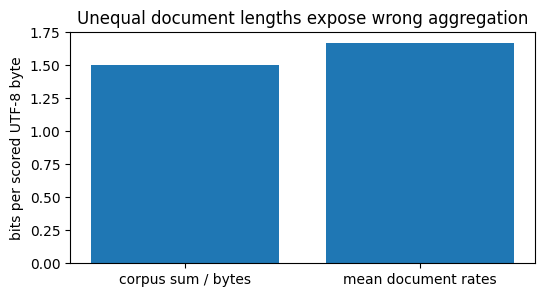

In [7]:
one = -math.log(.25)
two = -math.log(.5) - math.log(.5)
print("token perplexities", math.exp(one), math.exp(two/2))
print("same text bits/byte", aggregate_byte_scores([ByteScore(one, "a")])["bits_per_byte"],
      aggregate_byte_scores([ByteScore(two, "a")])["bits_per_byte"])
records = [ByteScore(math.log(4), "a"), ByteScore(math.log(16), "數")]
corpus = aggregate_byte_scores(records)
wrong_mean = (2 + 4/3)/2
print("corpus", corpus, "wrong document mean", wrong_mean)
try:
    aggregate_byte_scores([records[0], ByteScore(1., "b", ByteScoringContract(eos="included"))])
except ValueError as error:
    print("Incompatible score contract:", error)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["corpus sum / bytes", "mean document rates"], [corpus["bits_per_byte"], wrong_mean])
ax.set(ylabel="bits per scored UTF-8 byte", title="Unequal document lengths expose wrong aggregation")
plt.show()

### Reference explanation

The same text probability gives perplexities 4 and 2 because token counts differ. Its bits per byte remains 2 under the fixed raw-text contract. The corpus example totals six bits over four bytes: 1.5 bits/byte, rather than averaging document rates. `scored_text` must be the exact raw span corresponding to the summed NLL. Normalization, context, masks and EOS conventions must agree; these toy probabilities do not establish equivalent learned models. Read the plot's height as an aggregated rate, not a capability score.

![Reference plot: Reference solution. Axis labels identify the mechanism quantities.](../../figures/chapter-02/cs336-05_tokenizer_contracts-03.png)

Read this preview alongside the explanation above. Regenerate it by running the adjacent reference cell; simulated curves and retained measurements keep their stated evidence labels.
